# Gene-Level Uracil Enrichment Analysis for Plasmodium falciparum

This notebook reproduces the gene-level uracil enrichment analysis from Izrael et al., identifying enrichment in variant surface antigen (VSA) gene families including var and rif/stevor genes.

## 1. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pyBigWig
import os
from pathlib import Path
from scipy import stats

# Set up plotting style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
print("Libraries imported successfully!")

Libraries imported successfully!


## 2. Define Data Paths and Load BED Files for Gene Annotations

In [11]:
# Define paths
base_path = Path("/Users/richardizrael/Documents/Projects/udnaseq-reproducibility")
data_path = base_path / "data"
bed_path = data_path / "BED_files"
log2_bw_path = data_path / "log2_bw"

# Output directory for this analysis
output_dir = base_path / "antigen_uracil_enrichment"
output_dir.mkdir(exist_ok=True)

print(f"Base path: {base_path}")
print(f"BED files path: {bed_path}")
print(f"Log2 BigWig path: {log2_bw_path}")
print(f"Output directory: {output_dir}")

# Load BED files with gene annotations
# Column names: chrom, chromStart, chromEnd, name, score, strand
# Note: Some files include extra annotation columns; use usecols to keep only first 6
var_bed = pd.read_csv(bed_path / "var_genes" / "var_genes.bed", sep='\t', 
                       header=None, 
                       names=['chrom', 'chromStart', 'chromEnd', 'name', 'score', 'strand', 'extra'],
                       usecols=[0, 1, 2, 3, 4, 5])
rif_stevor_bed = pd.read_csv(bed_path / "rifinstrevor_genes.bed", sep='\t', 
                              header=None, 
                              names=['chrom', 'chromStart', 'chromEnd', 'name', 'score', 'strand'],
                              usecols=[0,1,2,3,4,5])

# Protein-coding BED may have varying columns; read flexibly and keep first six columns
prot_raw = pd.read_csv(bed_path / "ProteinCodingGenes.SurfaceSubtracted.bed", sep='\t', header=None, dtype=str)
# Determine how many columns are present and select up to 6
ncols = prot_raw.shape[1]
keep_cols = min(ncols, 6)
prot_df = prot_raw.iloc[:, :keep_cols].copy()
# Assign names for columns we have, add missing columns as NaN if fewer than 6
col_names = ['chrom', 'chromStart', 'chromEnd', 'name', 'score', 'strand']
prot_df.columns = col_names[:keep_cols]
for missing_col in col_names[keep_cols:]:
    prot_df[missing_col] = pd.NA
# Reorder to canonical order
prot_df = prot_df[col_names]
# Convert numeric columns where possible
prot_df['chromStart'] = pd.to_numeric(prot_df['chromStart'], errors='coerce').astype('Int64')
prot_df['chromEnd'] = pd.to_numeric(prot_df['chromEnd'], errors='coerce').astype('Int64')

protein_coding_bed = prot_df

print(f"\nVar genes: {len(var_bed)} genes loaded")
print(f"Rif/Stevor genes: {len(rif_stevor_bed)} genes loaded")
print(f"Protein-coding genes: {len(protein_coding_bed)} genes loaded")

print("\nVar genes sample:")
print(var_bed.head())
print("\nRif/Stevor genes sample:")
print(rif_stevor_bed.head())
print("\nProtein-coding genes sample:")
print(protein_coding_bed.head())

Base path: /Users/richardizrael/Documents/Projects/udnaseq-reproducibility
BED files path: /Users/richardizrael/Documents/Projects/udnaseq-reproducibility/data/BED_files
Log2 BigWig path: /Users/richardizrael/Documents/Projects/udnaseq-reproducibility/data/log2_bw
Output directory: /Users/richardizrael/Documents/Projects/udnaseq-reproducibility/antigen_uracil_enrichment

Var genes: 62 genes loaded
Rif/Stevor genes: 212 genes loaded
Protein-coding genes: 4737 genes loaded

Var genes sample:
         chrom  chromStart  chromEnd           name  score strand
0  Pf3D7_01_v3       29509     37126  PF3D7_0100100     60      +
1  Pf3D7_01_v3       42366     46507  PF3D7_0100300     60      -
2  Pf3D7_01_v3      607389    614893  PF3D7_0115700     60      -
3  Pf3D7_02_v3       25231     31168  PF3D7_0200100     60      +
4  Pf3D7_02_v3      916351    923648  PF3D7_0223500     60      -

Rif/Stevor genes sample:
         chrom  chromStart  chromEnd           name  score strand
0  Pf3D7_01_v3   

## 3. Load BigWig Files for Uracil Enrichment Data

In [4]:
# List available BigWig files
bw_files = sorted([f for f in os.listdir(log2_bw_path) if f.endswith('.bw')])
print(f"Available BigWig files: {len(bw_files)}")
for bw_file in bw_files:
    print(f"  - {bw_file}")

# We'll use the 3D7 replicates (UDNA IP vs INPUT log2 enrichment)
# These are the main U-DNA-Seq samples from the paper
bw_files_to_use = [
    "3d7_rep1.MAPQfiltered.IPvsINPUT.bin100bp.log2.bw",
    "3d7_rep2.MAPQfiltered.IPvsINPUT.bin100bp.log2.bw"
]

print(f"\nUsing BigWig files:")
for bw_file in bw_files_to_use:
    print(f"  - {bw_file}")

Available BigWig files: 7
  - 3d7_rep1.MAPQfiltered.IPvsINPUT.bin100bp.log2.bw
  - 3d7_rep2.MAPQfiltered.IPvsINPUT.bin100bp.log2.bw
  - DMSO.MAPQfiltered.IPvsINPUT.bin100bp.log2.bw
  - H3K4me3.IPvsINPUT.bin100bp.log2.bw
  - H3K9ac.IPvsINPUT.bin100bp.log2.bw
  - H3K9me3.IPvsINPUT.bin100bp.log2.bw
  - RAPA.MAPQfiltered.IPvsINPUT.bin100bp.log2.bw

Using BigWig files:
  - 3d7_rep1.MAPQfiltered.IPvsINPUT.bin100bp.log2.bw
  - 3d7_rep2.MAPQfiltered.IPvsINPUT.bin100bp.log2.bw


## 4. Calculate Average Uracil Enrichment per Gene

In [5]:
def get_avg_enrichment_from_bw(bw_file_path, chrom, start, end):
    """
    Extract average enrichment value from BigWig file for a genomic region.
    Handles cases where no data is available or region is invalid.
    """
    try:
        bw = pyBigWig.open(bw_file_path)
        # Get intervals with values
        intervals = bw.stats(chrom, start, end, type="mean")
        bw.close()
        
        if intervals is None or len(intervals) == 0:
            return np.nan
        
        # Calculate mean, filtering out None values
        values = [v for v in intervals if v is not None]
        if len(values) == 0:
            return np.nan
        
        return np.mean(values)
    except Exception as e:
        return np.nan

def calculate_gene_enrichments(bed_df, bw_files, bw_path):
    """
    Calculate average log2(uracil-enrichment) for each gene across BigWig files.
    """
    enrichment_data = []
    
    for idx, row in bed_df.iterrows():
        chrom = row['chrom']
        start = row['chromStart']
        end = row['chromEnd']
        gene_name = row['name']
        
        gene_enrichments = []
        for bw_file in bw_files:
            bw_path_full = bw_path / bw_file
            avg_enrichment = get_avg_enrichment_from_bw(str(bw_path_full), chrom, start, end)
            gene_enrichments.append(avg_enrichment)
        
        # Calculate mean across replicates (filtering NaNs)
        valid_enrichments = [e for e in gene_enrichments if not np.isnan(e)]
        if len(valid_enrichments) > 0:
            mean_enrichment = np.mean(valid_enrichments)
        else:
            mean_enrichment = np.nan
        
        enrichment_data.append({
            'gene_name': gene_name,
            'chrom': chrom,
            'start': start,
            'end': end,
            'enrichment': mean_enrichment,
            'rep1_enrichment': gene_enrichments[0] if len(gene_enrichments) > 0 else np.nan,
            'rep2_enrichment': gene_enrichments[1] if len(gene_enrichments) > 1 else np.nan
        })
    
    return pd.DataFrame(enrichment_data)

print("Calculating average enrichment for var genes...")
var_enrichment = calculate_gene_enrichments(var_bed, bw_files_to_use, log2_bw_path)
print(f"Var genes enrichment calculated: {len(var_enrichment)} genes")
print(var_enrichment.head())
print(f"Mean enrichment: {var_enrichment['enrichment'].mean():.4f}")
print(f"Genes with valid data: {var_enrichment['enrichment'].notna().sum()}\n")

print("Calculating average enrichment for rif/stevor genes...")
rif_stevor_enrichment = calculate_gene_enrichments(rif_stevor_bed, bw_files_to_use, log2_bw_path)
print(f"Rif/Stevor genes enrichment calculated: {len(rif_stevor_enrichment)} genes")
print(rif_stevor_enrichment.head())
print(f"Mean enrichment: {rif_stevor_enrichment['enrichment'].mean():.4f}")
print(f"Genes with valid data: {rif_stevor_enrichment['enrichment'].notna().sum()}")

Calculating average enrichment for var genes...
Var genes enrichment calculated: 62 genes
       gene_name        chrom   start     end  enrichment  rep1_enrichment  \
0  PF3D7_0100100  Pf3D7_01_v3   29509   37126    0.248199         0.236868   
1  PF3D7_0100300  Pf3D7_01_v3   42366   46507    0.021063        -0.050190   
2  PF3D7_0115700  Pf3D7_01_v3  607389  614893    0.272033         0.267695   
3  PF3D7_0200100  Pf3D7_02_v3   25231   31168    0.151598         0.121988   
4  PF3D7_0223500  Pf3D7_02_v3  916351  923648    0.301804         0.294283   

   rep2_enrichment  
0         0.259531  
1         0.092315  
2         0.276371  
3         0.181208  
4         0.309324  
Mean enrichment: 0.2373
Genes with valid data: 62

Calculating average enrichment for rif/stevor genes...
Rif/Stevor genes enrichment calculated: 212 genes
       gene_name        chrom  start    end  enrichment  rep1_enrichment  \
0  PF3D7_0100200  Pf3D7_01_v3  38981  40207    0.233993         0.070437   
1  PF3D

## 5. Prepare Data for Visualization

In [13]:
# Prepare list of BigWig files to use (replicates selected earlier)
bw_files = [
    log2_bw_path / "3d7_rep1.MAPQfiltered.IPvsINPUT.bin100bp.log2.bw",
    log2_bw_path / "3d7_rep2.MAPQfiltered.IPvsINPUT.bin100bp.log2.bw",
]

print("Calculating enrichments (this may take a moment)...")

# Calculate enrichments for each gene set
var_enrich_df = calculate_gene_enrichments(var_bed, bw_files, log2_bw_path)
var_enrich_df['gene_family'] = 'var genes'

rif_enrich_df = calculate_gene_enrichments(rif_stevor_bed, bw_files, log2_bw_path)
rif_enrich_df['gene_family'] = 'rif/stevor genes'

protein_enrich_df = calculate_gene_enrichments(protein_coding_bed, bw_files, log2_bw_path)
protein_enrich_df['gene_family'] = 'protein-coding genes'

# Combine all into a single dataframe
combined_df = pd.concat([var_enrich_df, rif_enrich_df, protein_enrich_df], ignore_index=True)

# Clean NaNs and prepare for stats & plotting
combined_df_clean = combined_df.dropna(subset=['enrichment']).copy()

# Basic summary
print(f"\nCombined dataset statistics:")
print(f"Total genes: {len(combined_df)}")
print(f"Genes with valid enrichment data: {len(combined_df_clean)}")

summary = combined_df_clean.groupby('gene_family')['enrichment'].describe()
print('\nSummary by gene family:')
print(summary)

# Statistical comparisons: var vs rif/stevor and var vs protein-coding
var_vals = combined_df_clean.loc[combined_df_clean['gene_family']=='var genes', 'enrichment']
rif_vals = combined_df_clean.loc[combined_df_clean['gene_family']=='rif/stevor genes', 'enrichment']
prot_vals = combined_df_clean.loc[combined_df_clean['gene_family']=='protein-coding genes', 'enrichment']

from scipy import stats

t_stat_v_r, p_val_v_r = stats.ttest_ind(var_vals, rif_vals, equal_var=False, nan_policy='omit')
t_stat_v_p, p_val_v_p = stats.ttest_ind(var_vals, prot_vals, equal_var=False, nan_policy='omit')

print('\nWelch\'s t-test comparing var and rif/stevor genes:')
print(f"t-statistic: {t_stat_v_r:.4f}")
print(f"p-value: {p_val_v_r:.6f}")
print(f"Mean var genes enrichment: {var_vals.mean():.4f}")
print(f"Mean rif/stevor genes enrichment: {rif_vals.mean():.4f}")

print('\nWelch\'s t-test comparing var and protein-coding genes:')
print(f"t-statistic: {t_stat_v_p:.4f}")
print(f"p-value: {p_val_v_p:.6f}")
print(f"Mean protein-coding genes enrichment: {prot_vals.mean():.4f}")

# Save combined data and summary to output directory
combined_csv = output_dir / 'gene_level_enrichment_data.csv'
summary_csv = output_dir / 'enrichment_summary_statistics.csv'
combined_df.to_csv(combined_csv, index=False)
summary.to_csv(summary_csv)

print(f"\nSaved combined enrichment data to: {combined_csv}")
print(f"Saved summary statistics to: {summary_csv}")

Calculating enrichments (this may take a moment)...

Combined dataset statistics:
Total genes: 5011
Genes with valid enrichment data: 5009

Summary by gene family:
                       count      mean       std       min       25%  \
gene_family                                                            
protein-coding genes  4735.0 -0.052270  0.110221 -1.096970 -0.107230   
rif/stevor genes       212.0  0.149650  0.082321 -0.098385  0.097031   
var genes               62.0  0.237275  0.085356 -0.119527  0.213865   

                           50%       75%       max  
gene_family                                         
protein-coding genes -0.047154  0.012335  0.393018  
rif/stevor genes      0.161095  0.204560  0.362148  
var genes             0.248872  0.284416  0.472620  

Welch's t-test comparing var and rif/stevor genes:
t-statistic: 7.1671
p-value: 0.000000
Mean var genes enrichment: 0.2373
Mean rif/stevor genes enrichment: 0.1497

Welch's t-test comparing var and protein-cod

## 6. Generate Violin Plot of Uracil Enrichment

Plot saved as '/Users/richardizrael/Documents/Projects/udnaseq-reproducibility/antigen_uracil_enrichment/gene_level_uracil_enrichment_violin.png'


/var/folders/6s/fx60sx9j6rndnwxkppsp3j5w0000gn/T/ipykernel_35267/1885768063.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(data=combined_df_clean, x='gene_family', y='enrichment', order=order, palette=['#2b83ba', '#f28e2b', '#6a9a3c'])
/var/folders/6s/fx60sx9j6rndnwxkppsp3j5w0000gn/T/ipykernel_35267/1885768063.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f'var genes\n(n={var_count})', f'rif/stevor genes\n(n={rif_count})', f'protein-coding genes\n(n={prot_count})'])


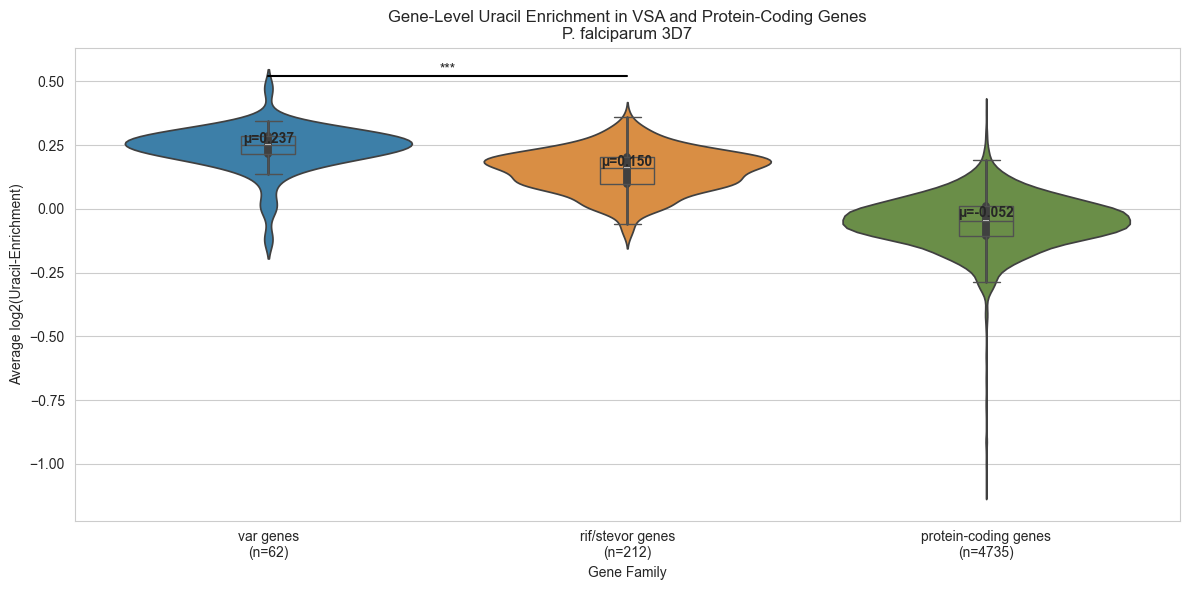

In [14]:
# Visualization: violin plot including protein-coding genes
plt.figure(figsize=(12,6))
order = ['var genes', 'rif/stevor genes', 'protein-coding genes']
ax = sns.violinplot(data=combined_df_clean, x='gene_family', y='enrichment', order=order, palette=['#2b83ba', '#f28e2b', '#6a9a3c'])

# Add median/box overlay
sns.boxplot(data=combined_df_clean, x='gene_family', y='enrichment', order=order,
            showcaps=True, boxprops={'facecolor':'none'}, showfliers=False, whiskerprops={'linewidth':1}, width=0.15)

# Annotate means
for i, fam in enumerate(order):
    vals = combined_df_clean.loc[combined_df_clean['gene_family']==fam, 'enrichment']
    mean_val = vals.mean()
    ax.text(i, mean_val + 0.02, f"µ={mean_val:.3f}", horizontalalignment='center', weight='bold')

# Add counts under x-ticks
var_count = len(combined_df_clean[combined_df_clean['gene_family']=='var genes'])
rif_count = len(combined_df_clean[combined_df_clean['gene_family']=='rif/stevor genes'])
prot_count = len(combined_df_clean[combined_df_clean['gene_family']=='protein-coding genes'])
ax.set_xticklabels([f'var genes\n(n={var_count})', f'rif/stevor genes\n(n={rif_count})', f'protein-coding genes\n(n={prot_count})'])

ax.set_ylabel('Average log2(Uracil-Enrichment)')
ax.set_xlabel('Gene Family')
ax.set_title('Gene-Level Uracil Enrichment in VSA and Protein-Coding Genes\nP. falciparum 3D7')

# Add statistical significance bar for var vs rif
# We computed p-values earlier: p_val_v_r and p_val_v_p
# Place bars accordingly
y_max = combined_df_clean['enrichment'].max()
bar_y = y_max + 0.05
ax.plot([0,1],[bar_y,bar_y], color='k')
ax.text(0.5, bar_y + 0.01, '***' if p_val_v_r < 0.001 else f'p={p_val_v_r:.3f}', horizontalalignment='center')

# Save figure into output directory
fig_path = output_dir / 'gene_level_uracil_enrichment_violin.png'
plt.tight_layout()
plt.savefig(fig_path, dpi=300)
print(f"Plot saved as '{fig_path}'")
plt.show()

## 7. Export Results Summary

In [ ]:
# Export detailed analysis report to output directory
report_path = output_dir / 'analysis_report.txt'
with open(report_path, 'w') as fh:
    fh.write('GENE-LEVEL URACIL ENRICHMENT ANALYSIS - SUMMARY REPORT\n')
    fh.write('=====================================================\n\n')
    fh.write('Analysis Overview:\n')
    fh.write('- Samples analyzed: 3D7 replicate 1 and 2\n')
    fh.write('- Gene families: var genes, rif/stevor genes, protein-coding genes\n')
    fh.write('- BigWig files used:\n')
    for p in bw_files:
        fh.write(f'  - {p.name}\n')
    fh.write('\nKey Findings:\n')
    fh.write(f"- var genes mean log2(uracil-enrichment): {var_vals.mean():.4f}\n")
    fh.write(f"- rif/stevor genes mean log2(uracil-enrichment): {rif_vals.mean():.4f}\n")
    fh.write(f"- protein-coding genes mean log2(uracil-enrichment): {prot_vals.mean():.4f}\n")
    fh.write('\nStatistical Significance:\n')
    fh.write(f"- var vs rif/stevor p-value: {p_val_v_r:.6f}\n")
    fh.write(f"- var vs protein-coding p-value: {p_val_v_p:.6f}\n")
    fh.write('\nOutput Files:\n')
    fh.write(f"- {combined_csv.name}: Full enrichment data for all genes\n")
    fh.write(f"- {summary_csv.name}: Summary statistics by gene family\n")
    fh.write(f"- {fig_path.name}: Violin plot visualization\n")

print(f"Analysis report saved to: {report_path}")

# For convenience, also print a list of files in output_dir
print('\nFiles in output directory:')
for f in sorted(output_dir.iterdir()):
    print('-', f.name)

Summary Statistics of Uracil Enrichment:
                  count    mean  median     std     min     max
gene_family                                                    
rif/stevor genes    212  0.1497  0.1611  0.0823 -0.0984  0.3621
var genes            62  0.2373  0.2489  0.0854 -0.1195  0.4726


GENE-LEVEL URACIL ENRICHMENT ANALYSIS - SUMMARY REPORT

Analysis Overview:
- Samples analyzed: 3D7 replica 1 and 2
- Gene families: var genes (n=62) and rif/stevor genes (n=212)
- BigWig files used:
  - 3d7_rep1.MAPQfiltered.IPvsINPUT.bin100bp.log2.bw
  - 3d7_rep2.MAPQfiltered.IPvsINPUT.bin100bp.log2.bw

Key Findings:
- var genes mean log2(uracil-enrichment): 0.2373
- rif/stevor genes mean log2(uracil-enrichment): 0.1497
- Difference: 0.0876

Statistical Significance:
- Welch's t-test p-value: 0.000000
- Significance level: ***

Interpretation:
The analysis reveals that variant surface antigen genes (var and rif/stevor) 
show enrichment in genomic uracil compared to the genome-wide background